# TMDB Movie Analysis

In [3]:
# Imports/setup
# Data from [https://www.kaggle.com/datasets/asaniczka/tmdb-movies-dataset-2023-930k-movies]
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import AutoMinorLocator, FuncFormatter
from scipy import stats

sns.set_theme(style="whitegrid")

In [4]:
# Load data
movies_raw = pd.read_csv("data/TMDB_movie_dataset_v11.csv", low_memory=False) # ~1.38M rows, takes a minute
PLOTS_DIR = Path("plots")
PLOTS_DIR.mkdir(exist_ok=True)
movies_raw.head()

,id,title,vote_average,vote_count,status,release_date,revenue,runtime,adult,backdrop_path,...,original_title,overview,popularity,poster_path,tagline,genres,production_companies,production_countries,spoken_languages,keywords
0,27205,Inception,8.364,34495,Released,2010-07-15,825532764,148,False,/8ZTVqvKDQ8emSGUEMjsS4yHAwrp.jpg,...,Inception,"Cobb, a skilled thief who commits corporate es...",83.952,/oYuLEt3zVCKq57qu2F8dT7NIa6f.jpg,Your mind is the scene of the crime.,"Action, Science Fiction, Adventure","Legendary Pictures, Syncopy, Warner Bros. Pict...","United Kingdom, United States of America","English, French, Japanese, Swahili","rescue, mission, dream, airplane, paris, franc..."
1,157336,Interstellar,8.417,32571,Released,2014-11-05,701729206,169,False,/pbrkL804c8yAv3zBZR4QPEafpAR.jpg,...,Interstellar,The adventures of a group of explorers who mak...,140.241,/gEU2QniE6E77NI6lCU6MxlNBvIx.jpg,Mankind was born on Earth. It was never meant ...,"Adventure, Drama, Science Fiction","Legendary Pictures, Syncopy, Lynda Obst Produc...","United Kingdom, United States of America",English,"rescue, future, spacecraft, race against time,..."
2,155,The Dark Knight,8.512,30619,Released,2008-07-16,1004558444,152,False,/nMKdUUepR0i5zn0y1T4CsSB5chy.jpg,...,The Dark Knight,Batman raises the stakes in his war on crime. ...,130.643,/qJ2tW6WMUDux911r6m7haRef0WH.jpg,Welcome to a world without rules.,"Drama, Action, Crime, Thriller","DC Comics, Legendary Pictures, Syncopy, Isobel...","United Kingdom, United States of America","English, Mandarin","joker, sadism, chaos, secret identity, crime f..."
3,19995,Avatar,7.573,29815,Released,2009-12-15,2923706026,162,False,/vL5LR6WdxWPjLPFRLe133jXWsh5.jpg,...,Avatar,"In the 22nd century, a paraplegic Marine is di...",79.932,/kyeqWdyUXW608qlYkRqosgbbJyK.jpg,Enter the world of Pandora.,"Action, Adventure, Fantasy, Science Fiction","Dune Entertainment, Lightstorm Entertainment, ...","United States of America, United Kingdom","English, Spanish","future, society, culture clash, space travel, ..."
4,24428,The Avengers,7.710,29166,Released,2012-04-25,1518815515,143,False,/9BBTo63ANSmhC4e6r62OJFuK2GL.jpg,...,The Avengers,When an unexpected enemy emerges and threatens...,98.082,/RYMX2wcKCBAr24UyPD7xwmjaTn.jpg,Some assembly required.,"Science Fiction, Action, Adventure",Marvel Studios,United States of America,"English, Hindi, Russian","new york city, superhero, shield, based on com..."


In [5]:
print("Shape:", movies_raw.shape)          # R: dim()
print("Type:", type(movies_raw).__name__)  # R: data.class()
print("Columns:", list(movies_raw.columns))  # R: names()

Shape: (1516495, 24)
Type: DataFrame
Columns: ['id', 'title', 'vote_average', 'vote_count', 'status', 'release_date', 'revenue', 'runtime', 'adult', 'backdrop_path', 'budget', 'homepage', 'imdb_id', 'original_language', 'original_title', 'overview', 'popularity', 'poster_path', 'tagline', 'genres', 'production_companies', 'production_countries', 'spoken_languages', 'keywords']


In [7]:
# Load into SQLite
con = sqlite3.connect("data/tmdb.db")

# Write dataframe to SQLite (one-time, takes a few minutes)
movies_raw.to_sql("movies", con, if_exists="replace", index=False, chunksize=50_000)

# Confirm the table loaded 
pd.read_sql("SELECT name FROM sqlite_master WHERE type = 'table'", con)

,name
0,movies


In [8]:
# Remove adult films for data
pd.read_sql("SELECT DISTINCT adult, typeof(adult) AS type FROM movies LIMIT 10", con)

,adult,type
0,0,integer
1,1,integer


In [9]:
# Query the filtered dataset
query = '''
SELECT
    id,
    title,
    release_date,
    vote_average,
    vote_count,
    popularity,
    runtime,
    genres,
    original_language,
    status
FROM movies
WHERE status = 'Released'
  AND release_date IS NOT NULL
  AND release_date != ''
  AND (
        adult = 0
        OR LOWER(CAST(adult AS TEXT)) IN ('false', '0')
    )
'''

movies = pd.read_sql(query, con)

movies["release_date"] = pd.to_datetime(movies["release_date"], errors="coerce")
movies["release_year"] = movies["release_date"].dt.year

movies = movies[
    movies["release_date"].notna()
    & movies["release_year"].between(1980, 2023)
    & (movies["vote_count"] >= 10)
].reset_index(drop=True)

movies["release_year"] = movies["release_year"].astype(int)

print("Rows after filtering:", len(movies))

Rows after filtering: 61884


In [10]:
# Remove adult titles that TMDB has mislabelled as adult = 0 (found during dashboard review)
mislabelled = movies[movies["title"].str.contains("Yua Mikami", na=False)]
print(mislabelled[["id", "title", "vote_count", "popularity"]])

EXCLUDE_IDS = mislabelled["id"].tolist()
movies = movies[~movies["id"].isin(EXCLUDE_IDS)].reset_index(drop=True)
print("Rows after exclusion:", len(movies))

Empty DataFrame
Columns: [id, title, vote_count, popularity]
Index: []
Rows after exclusion: 61884


In [11]:
# Summary statistics
summary = pd.DataFrame({
    "total_movies":   [len(movies)],
    "avg_rating":     [round(movies["vote_average"].mean(), 2)],
    "median_rating":  [round(movies["vote_average"].median(), 2)],
    "avg_runtime":    [round(movies["runtime"].mean(), 1)],
    "avg_popularity": [round(movies["popularity"].mean(), 2)],
})
summary

,total_movies,avg_rating,median_rating,avg_runtime,avg_popularity
0,61884,6.12,6.2,94.5,8.19


In [13]:
# Split genres into one row per movie–genre pair
# Genres are comma-separated strings, e.g. "Action, Adventure"
genres_df = (
    movies[["id", "title", "release_year", "vote_average", "vote_count", "popularity", "genres"]]
    .assign(genres=lambda d: d["genres"]
            .str.replace(r"[\[\]']", "", regex=True)
            .str.split(r",\s*"))
    .explode("genres")
)
genres_df = genres_df[genres_df["genres"].notna() & (genres_df["genres"] != "")].reset_index(drop=True)

print("Genre rows:", len(genres_df))

Genre rows: 131082


In [14]:
# # Plots
# Palette: seaborn's "flare" (warm orange → deep plum)
# Ranked bar charts use it as a gradient: darker = higher value
BAR_PALETTE = "flare"
LINE_PALETTE = sns.color_palette("flare", 6)
MAIN_COLOR = sns.color_palette("flare", 10)[6]

comma = FuncFormatter(lambda x, _: f"{x:,.0f}")


def num_label(x, digits):
    # 6.70 -> "6.7", 1111.0 -> "1111"
    return f"{round(x, digits):g}"


def finish(fig, ax, title, filename, caption="Source: TMDB", subtitle=None):
    ax.set_title(title, loc="left", fontsize=14, fontweight="bold", pad=24 if subtitle else 8)
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=11, va="bottom")
    fig.text(0.99, 0.01, caption, ha="right", va="bottom", fontsize=9, color="gray")
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    fig.savefig(f"plots/{filename}", dpi=150)
    plt.show()

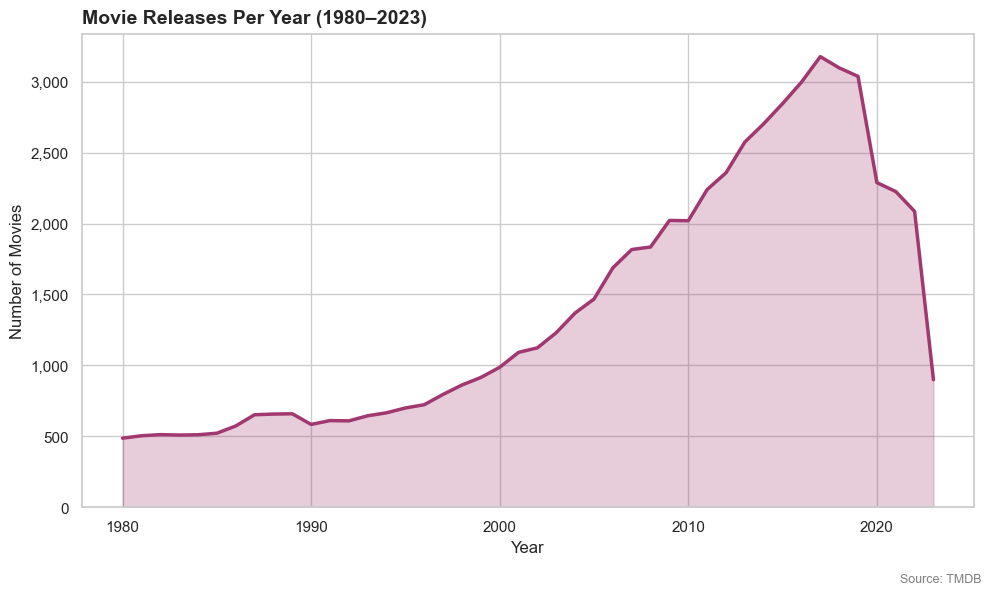

In [15]:
# Plot 1- Movie releases per year
per_year = movies["release_year"].value_counts().sort_index().reset_index()
per_year.columns = ["release_year", "n"]

fig, ax = plt.subplots(figsize=(10, 6))
sns.lineplot(data=per_year, x="release_year", y="n", color=MAIN_COLOR, linewidth=2.5, ax=ax)
ax.fill_between(per_year["release_year"], per_year["n"], color=MAIN_COLOR, alpha=0.25)
ax.yaxis.set_major_formatter(comma)
ax.set(xlabel="Year", ylabel="Number of Movies", ylim=(0, None))
finish(fig, ax, "Movie Releases Per Year (1980–2023)", "01_releases_per_year.png")

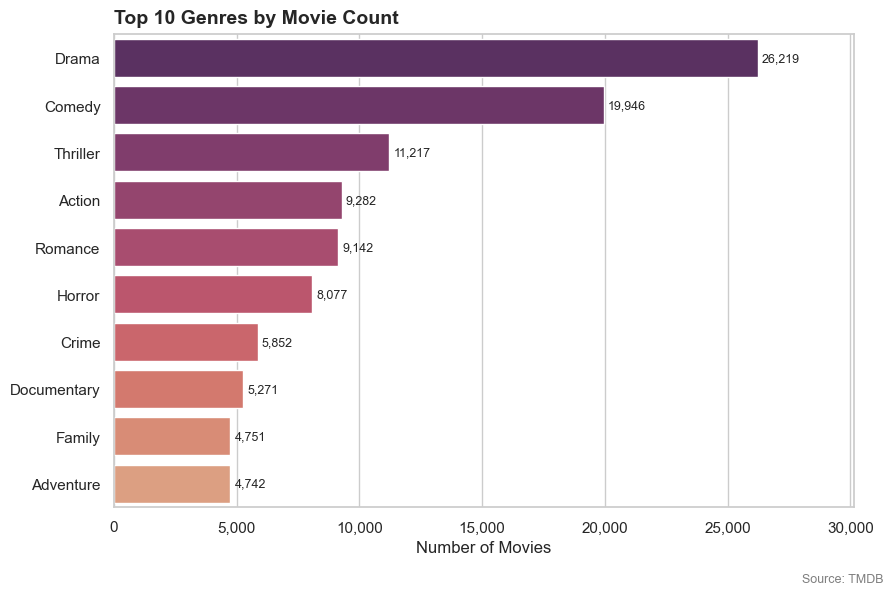

In [16]:
# Plot 2- Top 10 genres by movie count
genre_counts = (
    genres_df.groupby("genres").size().reset_index(name="n")
    .sort_values(["n", "genres"], ascending=[False, True], kind="stable")
)
top10_count = genre_counts.head(10)

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(data=top10_count, x="n", y="genres", hue="genres",
            palette=BAR_PALETTE + "_r", legend=False, ax=ax)
for bars in ax.containers:
    ax.bar_label(bars, labels=[f"{v:,.0f}" for v in bars.datavalues], padding=3, fontsize=9)
ax.set_xlim(0, top10_count["n"].max() * 1.15)
ax.xaxis.set_major_formatter(comma)
ax.set(xlabel="Number of Movies", ylabel="")
finish(fig, ax, "Top 10 Genres by Movie Count", "02_top_genres.png")

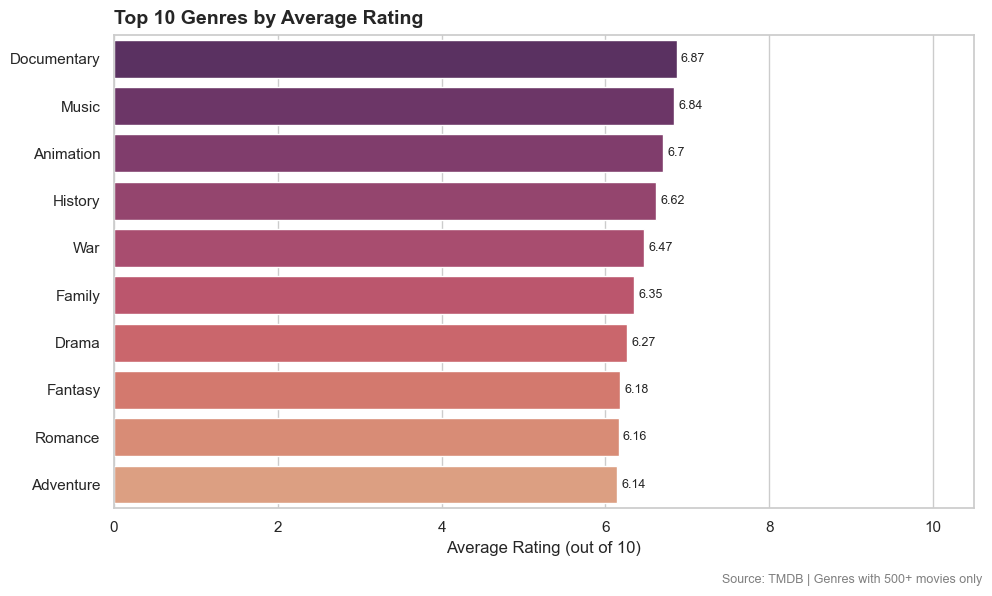

In [17]:
# Plot 3- Top 10 genres by average rating (genres with 500+ movies)
genre_ratings = (
    genres_df.groupby("genres")
    .agg(avg_rating=("vote_average", "mean"), n=("vote_average", "size"))
    .reset_index()
)
top10_rating = (genre_ratings[genre_ratings["n"] >= 500]
                .nlargest(10, "avg_rating", keep="all")
                .sort_values("avg_rating", ascending=False))

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=top10_rating, x="avg_rating", y="genres", hue="genres",
            palette=BAR_PALETTE + "_r", legend=False, ax=ax)
for bars in ax.containers:
    ax.bar_label(bars, labels=[num_label(v, 2) for v in bars.datavalues], padding=3, fontsize=9)
ax.set_xlim(0, 10.5)
ax.set(xlabel="Average Rating (out of 10)", ylabel="")
finish(fig, ax, "Top 10 Genres by Average Rating", "03_rating_by_genre.png",
       caption="Source: TMDB | Genres with 500+ movies only")

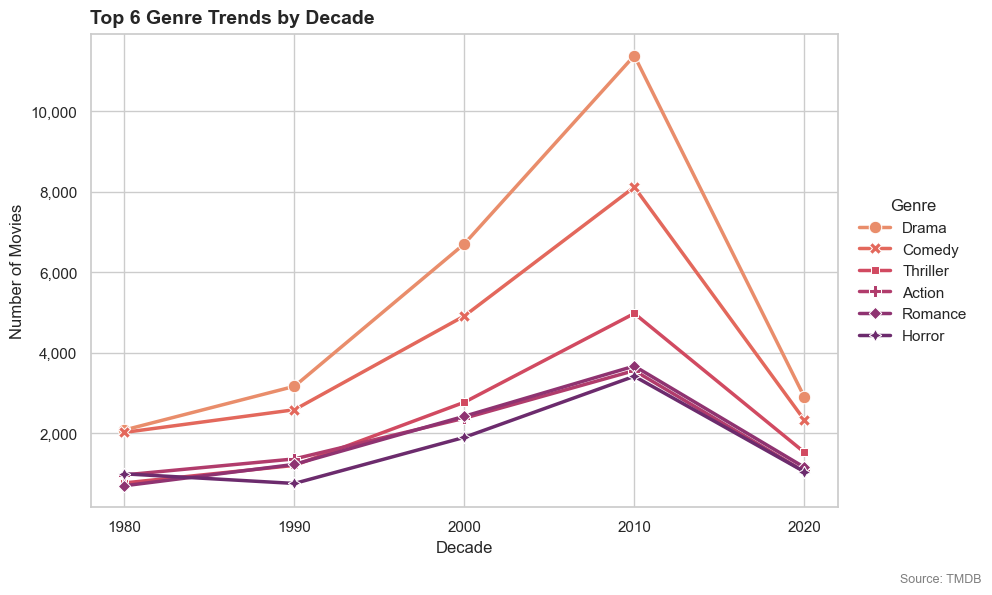

In [18]:
# Plot 4-  Top 6 genre trends by decade
top6_genres = genre_counts.head(6)["genres"].tolist()   # ordered largest → smallest

decade_counts = (
    genres_df[genres_df["genres"].isin(top6_genres)]
    .assign(decade=lambda d: (d["release_year"] // 10) * 10)
    .groupby(["decade", "genres"]).size().reset_index(name="n")
)

fig, ax = plt.subplots(figsize=(10, 6))
sns.lineplot(data=decade_counts, x="decade", y="n", hue="genres", hue_order=top6_genres,
            style="genres", style_order=top6_genres, markers=True, dashes=False,
            palette=LINE_PALETTE, markersize=9, linewidth=2.5, ax=ax)   # marker shape per genre
ax.set_xticks(range(1980, 2030, 10))
ax.yaxis.set_major_formatter(comma)
ax.set(xlabel="Decade", ylabel="Number of Movies")
sns.move_legend(ax, "center left", bbox_to_anchor=(1.01, 0.5), title="Genre", frameon=False)
finish(fig, ax, "Top 6 Genre Trends by Decade", "04_genre_trends_decade.png")

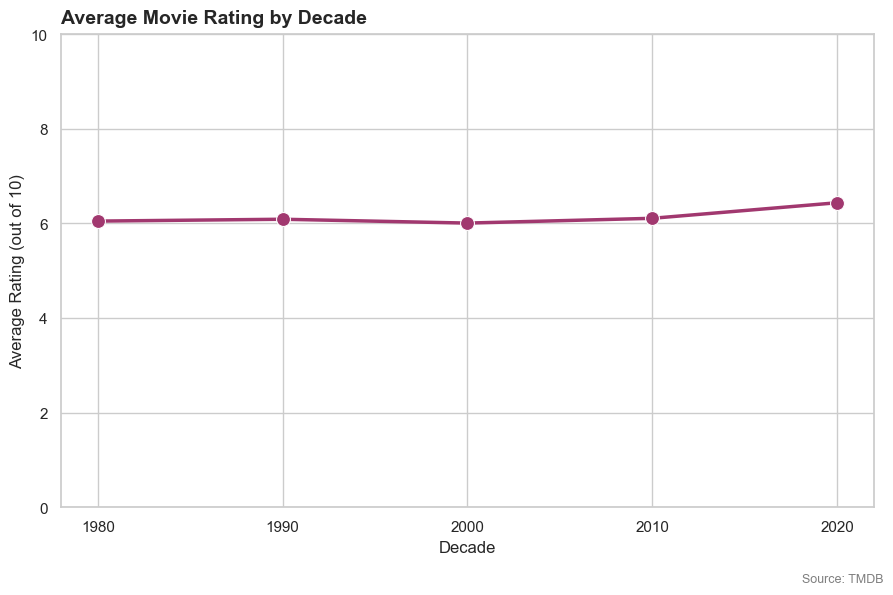

In [19]:
# Plot 5 - Average rating by decade
decade_rating = (
    movies.assign(decade=(movies["release_year"] // 10) * 10)
    .groupby("decade")
    .agg(avg_rating=("vote_average", "mean"), n=("vote_average", "size"))
    .reset_index()
)

fig, ax = plt.subplots(figsize=(9, 6))
sns.lineplot(data=decade_rating, x="decade", y="avg_rating", color=MAIN_COLOR,
            marker="o", markersize=10, linewidth=2.5, ax=ax)
ax.set_xticks(range(1980, 2030, 10))
ax.set(xlabel="Decade", ylabel="Average Rating (out of 10)", ylim=(0, 10))
finish(fig, ax, "Average Movie Rating by Decade", "05_rating_by_decade.png")

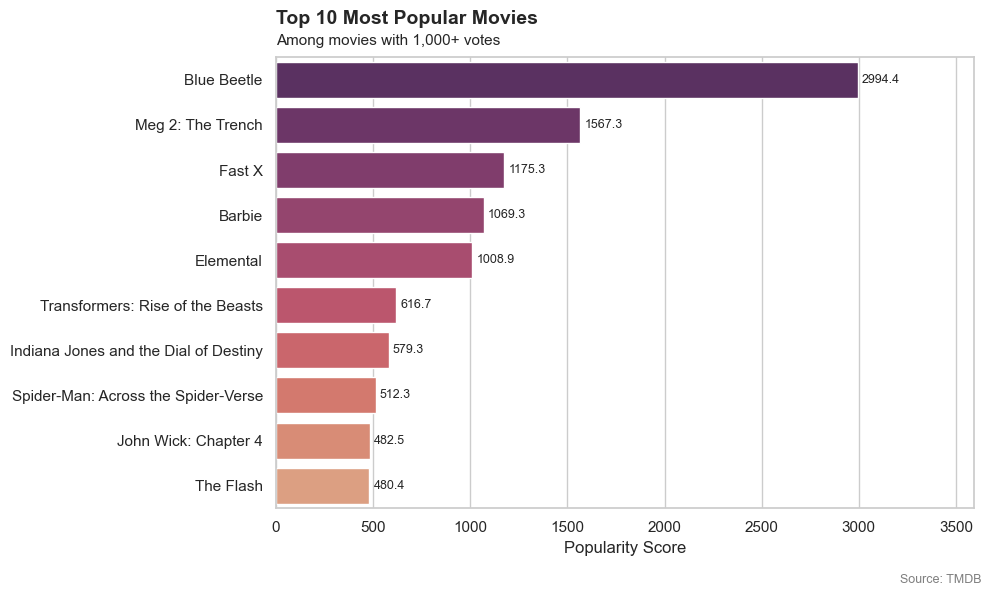

In [20]:
# Plot 6- Top 10 most popular movies 
MIN_VOTES = 1000

top_popular = (movies[movies["vote_count"] >= MIN_VOTES]
              .nlargest(10, "popularity", keep="all")
              .sort_values("popularity", ascending=False))

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=top_popular, x="popularity", y="title", hue="title",
            palette=BAR_PALETTE + "_r", legend=False, ax=ax)
for bars in ax.containers:
    ax.bar_label(bars, labels=[num_label(v, 1) for v in bars.datavalues], padding=3, fontsize=9)
ax.set_xlim(0, top_popular["popularity"].max() * 1.2)
ax.set(xlabel="Popularity Score", ylabel="")
finish(fig, ax, "Top 10 Most Popular Movies", "06_most_popular.png",
       subtitle=f"Among movies with {MIN_VOTES:,}+ votes")

## Statistical analysis

### Pearson correlation: popularity vs. rating
Correlation coefficient *r* ranges from −1 to 1:
- *r* > 0: as popularity increases, ratings tend to increase
- *r* < 0: as popularity increases, ratings tend to decrease
- *r* = 0: no linear relationship

In [21]:
pair = movies[["popularity", "vote_average"]].dropna()   # R's cor.test drops incomplete pairs
cor = stats.pearsonr(pair["popularity"], pair["vote_average"])
ci = cor.confidence_interval(confidence_level=0.95)
n = len(pair)
t_stat = cor.statistic * np.sqrt((n - 2) / (1 - cor.statistic**2))

print("Pearson's product-moment correlation")
print(f"t = {t_stat:.4f}, df = {n - 2}, p-value = {cor.pvalue:.4g}")
print(f"95% CI: [{ci.low:.4f}, {ci.high:.4f}]")
print(f"Correlation coefficient: {cor.statistic:.3f}")

Pearson's product-moment correlation
t = 21.4486, df = 61882, p-value = 1.105e-101
95% CI: [0.0781, 0.0937]
Correlation coefficient: 0.086


### Welch two-sample t-test: Action vs. Drama ratings
- H₀: no difference in mean rating between Action and Drama
- H₁: a difference exists

`equal_var=False` gives Welch's test, which is R's `t.test()` default.

In [22]:
action_ratings = genres_df.loc[genres_df["genres"] == "Action", "vote_average"].dropna()
drama_ratings  = genres_df.loc[genres_df["genres"] == "Drama",  "vote_average"].dropna()

t_result = stats.ttest_ind(action_ratings, drama_ratings, equal_var=False)
t_ci = t_result.confidence_interval(confidence_level=0.95)

print("Welch Two Sample t-test")
print(f"t = {t_result.statistic:.4f}, df = {t_result.df:.1f}, p-value = {t_result.pvalue:.4g}")
print(f"95% CI for difference in means (Action − Drama): [{t_ci.low:.4f}, {t_ci.high:.4f}]")
print(f"Mean Action: {action_ratings.mean():.4f} | Mean Drama: {drama_ratings.mean():.4f}")

print("\nConclusion:")
if t_result.pvalue < 0.05:
    print(f"p = {t_result.pvalue:.4f} < 0.05 — Significant difference in ratings between Action and Drama movies.")
else:
    print(f"p = {t_result.pvalue:.4f} >= 0.05 — No significant difference detected.")

Welch Two Sample t-test
t = -24.6236, df = 13887.6, p-value = 4.479e-131
95% CI for difference in means (Action − Drama): [-0.3405, -0.2903]
Mean Action: 5.9537 | Mean Drama: 6.2691

Conclusion:
p = 0.0000 < 0.05 — Significant difference in ratings between Action and Drama movies.


In [23]:
(
    genres_df[genres_df["genres"].isin(["Action", "Drama"])]
    .groupby("genres")
    .agg(avg_rating=("vote_average", "mean"), n=("vote_average", "size"))
    .round({"avg_rating": 3})
    .reset_index()
)

,genres,avg_rating,n
0,Action,5.954,9282
1,Drama,6.269,26219


## Export for Tableau

Same file names and column order as the R export, so the existing Tableau data sources can be refreshed against these files.

In [24]:
movies.to_csv("data/movies_filtered.csv", index=False, date_format="%Y-%m-%d")
genres_df.to_csv("data/genres_exploded.csv", index=False)

con.close()
print("Database connection closed. Analysis complete!")
print("Plots saved to the plots/ folder.")

Database connection closed. Analysis complete!
Plots saved to the plots/ folder.
